<a href="https://colab.research.google.com/github/LatikaaTejus/Toxic-comment-classification/blob/main/Toxic_msg_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
!pip install -q groq pandas scikit-learn

In [13]:
import os
import time
import pandas as pd
from google.colab import userdata
from groq import Groq
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# Initialize Groq Client
api_key = userdata.get('GROQ_API_KEY')
client = Groq(api_key=api_key)

# Define Zero-Shot Prompt Template
prompt_template = """Read the following comment and determine if it is toxic or not toxic.
Toxic means rude, disrespectful, insulting, threatening, or hateful.

Comment: "{comment}"

Respond with only one word: either "toxic" or "not_toxic". Do not explain your answer."""

In [21]:
from groq import Groq

client = Groq(api_key=NEW_KEY) # your active Groq key

try:
    response = client.chat.completions.create(
        model="openai/gpt-oss-20b",
        messages=[{"role": "user", "content": "Say hello in one word."}],
        max_tokens=10
    )
    print("Success:", response.choices[0].message.content)
except Exception as e:
    print("Error:", e)

Success: 


In [22]:
import time

predictions = []

for i, row in sample_df.iterrows():
    prompt = prompt_template.format(comment=row['comment_text'])
    try:
        response = client.chat.completions.create(
            model="openai/gpt-oss-20b",
            messages=[{"role": "user", "content": prompt}],
            max_tokens=20,
            temperature=0.0
        )
        result = response.choices[0].message.content.strip().lower()
    except Exception as e:
        result = "error"
        print(f"Row {i} failed: {e}")

    predictions.append(result)
    time.sleep(0.3)

sample_df['prediction_zero_shot'] = predictions
print(sample_df['prediction_zero_shot'].value_counts())

prediction_zero_shot
    100
Name: count, dtype: int64


In [23]:
# Filter out any errors if they occurred
clean_df = sample_df[sample_df['prediction_zero_shot'] != 'error'].copy()

# Map the text predictions (toxic/not_toxic) into binary numbers (1/0) to match real labels
clean_df['predicted_label'] = clean_df['prediction_zero_shot'].apply(lambda x: 1 if 'toxic' in x else 0)

# Import evaluation metrics from sklearn
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# Calculate metrics
acc = accuracy_score(clean_df['toxic'], clean_df['predicted_label'])
prec = precision_score(clean_df['toxic'], clean_df['predicted_label'], zero_division=0)
rec = recall_score(clean_df['toxic'], clean_df['predicted_label'], zero_division=0)

# Print results cleanly
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(clean_df['toxic'], clean_df['predicted_label']))

Accuracy:  0.5000
Precision: 0.0000
Recall:    0.0000

Confusion Matrix:
[[50  0]
 [50  0]]


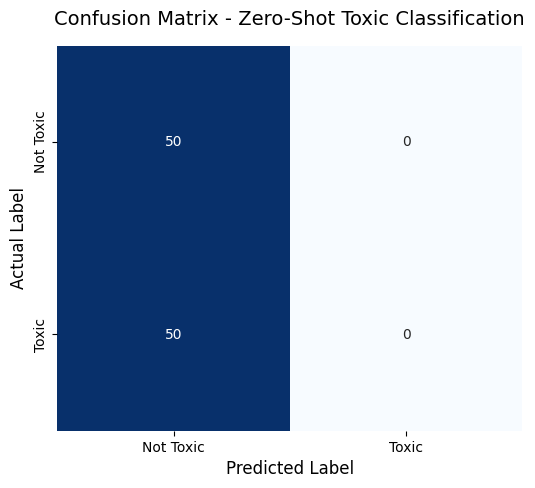

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm = confusion_matrix(clean_df['toxic'], clean_df['predicted_label'])

# Plotting the heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Not Toxic', 'Toxic'],
            yticklabels=['Not Toxic', 'Toxic'])

plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.title('Confusion Matrix - Zero-Shot Toxic Classification', fontsize=14, pad=15)
plt.show()